## Run initial SUMMA model tests ##

In [6]:
from pathlib import Path

# add auto reload for jupyter magic
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [19]:
from pathlib import Path

from snowda.workflows.run_summa import run_summa

config_path = Path("../runs/examples/ross_summa_deterministic_era5.yaml")
run_dir = run_summa(config_path)

print("Summa run directory:", run_dir)

2026-09-16 16:38:44 | INFO     | snowda.snowda.config.pysummada | output_dir not set; defaulting to /Users/dcasson/GitHub/snowda/outputs/ross_summa_deterministic
2026-09-16 16:38:44 | INFO     | snowda.snowda.workflows.run_summa | snowda SUMMA deterministic run starting
2026-09-16 16:38:44 | INFO     | snowda.snowda.workflows.run_summa | Config: ../runs/examples/ross_summa_deterministic_era5.yaml
2026-09-16 16:38:44 | INFO     | snowda.snowda.workflows.run_summa | Run dir: /Users/dcasson/GitHub/snowda/outputs/ross_summa_deterministic/20260916T223844Z
2026-09-16 16:38:44 | INFO     | snowda.snowda.workflows.run_summa | Wrote config snapshot: /Users/dcasson/GitHub/snowda/outputs/ross_summa_deterministic/20260916T223844Z/config.resolved.json
2026-09-16 16:38:44 | INFO     | snowda.snowda.io.summa_ensemble | Creating output directories
2026-09-16 16:38:44 | INFO     | snowda.snowda.io.summa_ensemble | Deleting ensemble files in /Users/dcasson/Data/snowda/summa/ross_lumped/settings/SUMMA
20

Summa run directory: /Users/dcasson/GitHub/snowda/outputs/ross_summa_deterministic/20260916T223844Z


In [ ]:
from snowda.workflows.evaluate_streamflow import run_evaluation
run_evaluation(sim_nc, obs_csv, output_dir=..., resample="1D")

In [6]:
# Option B: Run SUMMA fSCA workflow (requires existing SUMMA outputs)
from snowda.workflows.run_summa_fsca import run_summa_fsca


config_path = Path("../runs/examples/chena_summa_fsca.yaml").resolve()
run_dir = run_summa_fsca(config_path)
print("fSCA run dir:", run_dir)

2026-01-19 14:23:40 | INFO     | snowda.snowda.workflows.run_summa_fsca | snowda fSCA run starting
2026-01-19 14:23:40 | INFO     | snowda.snowda.workflows.run_summa_fsca | Config: /Users/dcasson/GitHub/snowda/runs/examples/chena_summa_fsca.yaml
2026-01-19 14:23:40 | INFO     | snowda.snowda.workflows.run_summa_fsca | Run dir: /Users/dcasson/Data/snowda/summa/chena/output/20260119T212340Z
2026-01-19 14:23:40 | INFO     | snowda.snowda.workflows.run_summa_fsca | Wrote config snapshot: /Users/dcasson/Data/snowda/summa/chena/output/20260119T212340Z/config.resolved.yaml
2026-01-19 14:23:40 | INFO     | snowda.snowda.io.summa_fsca | Preparing SUMMA fSCA input from [PosixPath('/Users/dcasson/GitHub/snowda/outputs/chena_summa_minimal/chena_pysumma_run_timestep.nc')]
2026-01-19 14:23:41 | WARNING  | snowda.snowda.io.summa_fsca | Unit conversion failed (unsupported operand type(s) for -: 'ParserHelper' and 'int'). Proceeding without conversions.
2026-01-19 14:23:43 | INFO     | snowda.snowda.io

fSCA run dir: /Users/dcasson/Data/snowda/summa/chena/output/20260119T212340Z


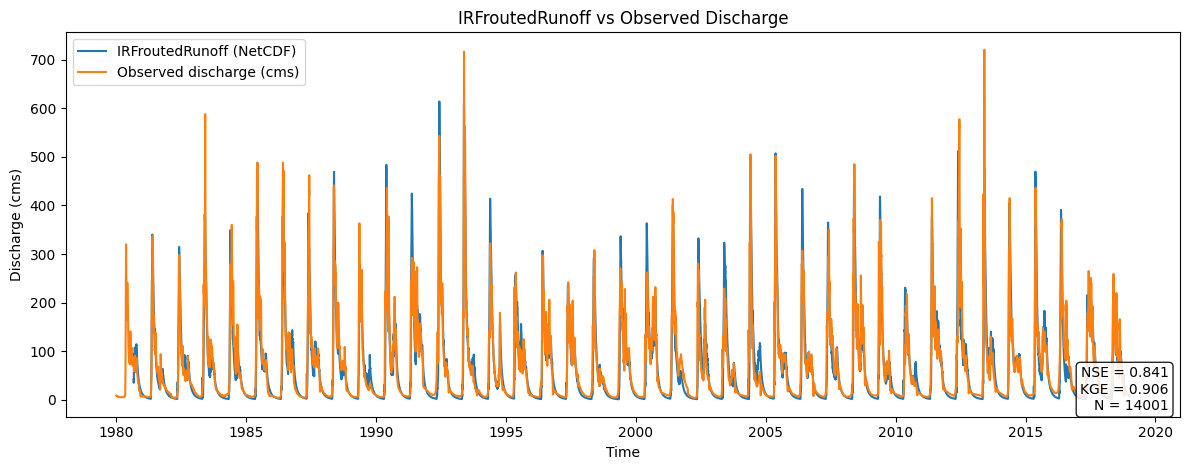

In [21]:
from __future__ import annotations

from dataclasses import dataclass
from typing import Optional, Tuple, Union

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt


def nse(sim: np.ndarray, obs: np.ndarray) -> float:
    """Nash–Sutcliffe Efficiency."""
    sim = np.asarray(sim, dtype=float)
    obs = np.asarray(obs, dtype=float)

    m = np.isfinite(sim) & np.isfinite(obs)
    sim, obs = sim[m], obs[m]
    if sim.size < 2:
        return np.nan

    denom = np.sum((obs - np.mean(obs)) ** 2)
    if denom == 0:
        return np.nan
    return 1.0 - np.sum((obs - sim) ** 2) / denom


def kge(sim: np.ndarray, obs: np.ndarray) -> float:
    """Kling–Gupta Efficiency (Gupta et al., 2009)."""
    sim = np.asarray(sim, dtype=float)
    obs = np.asarray(obs, dtype=float)

    m = np.isfinite(sim) & np.isfinite(obs)
    sim, obs = sim[m], obs[m]
    if sim.size < 2:
        return np.nan

    # Pearson r
    if np.std(sim) == 0 or np.std(obs) == 0:
        r = np.nan
    else:
        r = np.corrcoef(sim, obs)[0, 1]

    mu_s, mu_o = np.mean(sim), np.mean(obs)
    sd_s, sd_o = np.std(sim, ddof=1), np.std(obs, ddof=1)

    alpha = sd_s / sd_o if sd_o != 0 else np.nan
    beta = mu_s / mu_o if mu_o != 0 else np.nan

    if not (np.isfinite(r) and np.isfinite(alpha) and np.isfinite(beta)):
        return np.nan

    return 1.0 - np.sqrt((r - 1.0) ** 2 + (alpha - 1.0) ** 2 + (beta - 1.0) ** 2)


def plot_irfroutedrunoff_vs_discharge(
    nc_path: Optional[str] = None,
    csv_path: Optional[str] = None,
    *,
    irf_var: str = "IRFroutedRunoff",
    seg_index: int = 0,
    csv_datetime_col: Optional[str] = None,
    csv_discharge_col: Optional[str] = None,
    resample_rule: str = "D",
    agg: str = "mean",
    timezone: Optional[str] = None,
    out_png: Optional[str] = None,
    title: Optional[str] = None,
    start: Optional[Union[str, pd.Timestamp]] = None,
    stop: Optional[Union[str, pd.Timestamp]] = None,
) -> Tuple[plt.Figure, plt.Axes, Optional[float], Optional[float]]:
    """
    Read IRFroutedRunoff from NetCDF and/or discharge (cms) from CSV, align in time if both provided,
    compute NSE + KGE if both present, and plot available series.

    Optional start/stop arguments bound the plotting, metric and series period.

    Returns: (fig, ax, NSE, KGE) -- NSE/KGE are None if only one input provided.
    """
    sim = None
    obs = None

    # --- Read Model Results ---
    if nc_path is not None:
        ds = xr.open_dataset(nc_path)
        if irf_var not in ds:
            raise KeyError(f"Variable '{irf_var}' not found in {nc_path}. Available: {list(ds.data_vars)}")
        da = ds[irf_var]
        if "seg" in da.dims:
            da = da.isel(seg=seg_index)
        sim = da.to_series()
        sim.index = pd.to_datetime(sim.index)
        if timezone:
            if sim.index.tz is None:
                sim.index = sim.index.tz_localize(timezone)
            else:
                sim.index = sim.index.tz_convert(timezone)
        if resample_rule:
            if agg.lower() == "mean":
                sim = sim.resample(resample_rule).mean()
            elif agg.lower() == "sum":
                sim = sim.resample(resample_rule).sum()
            else:
                raise ValueError("agg must be 'mean' or 'sum'")

    # --- Read Observations ---
    if csv_path is not None:
        df = pd.read_csv(csv_path)
        if csv_datetime_col is None:
            for c in ["datetime", "date", "time", "timestamp", "Datetime", "DATE", "Date"]:
                if c in df.columns:
                    csv_datetime_col = c
                    break
        if csv_discharge_col is None:
            for c in ["discharge_cms", "discharge", "Q", "q", "flow", "streamflow", "Discharge_cms"]:
                if c in df.columns:
                    csv_discharge_col = c
                    break
        if csv_datetime_col is None or csv_discharge_col is None:
            if df.shape[1] < 2:
                raise ValueError("CSV must have at least 2 columns (datetime, discharge).")
            csv_datetime_col = df.columns[0]
            csv_discharge_col = df.columns[1]
        obs_df = df[[csv_datetime_col, csv_discharge_col]].copy()
        obs_df[csv_datetime_col] = pd.to_datetime(obs_df[csv_datetime_col])
        obs_df = obs_df.set_index(csv_datetime_col).sort_index()
        obs_df = obs_df.rename(columns={csv_discharge_col: "discharge_cms"})
        obs = obs_df["discharge_cms"].astype(float)

        if timezone:
            if obs.index.tz is None:
                obs.index = obs.index.tz_localize(timezone)
            else:
                obs.index = obs.index.tz_convert(timezone)
        if resample_rule:
            if agg.lower() == "mean":
                obs = obs.resample(resample_rule).mean()
            elif agg.lower() == "sum":
                obs = obs.resample(resample_rule).sum()

    # --- Restrict to desired time bounds if provided ---
    if start is not None or stop is not None:
        # To Timestamp for comparison
        if start is not None:
            start_dt = pd.to_datetime(start)
        else:
            start_dt = None
        if stop is not None:
            stop_dt = pd.to_datetime(stop)
        else:
            stop_dt = None

        if sim is not None:
            sim = sim.loc[
                (slice(start_dt, stop_dt))
            ]
        if obs is not None:
            obs = obs.loc[
                (slice(start_dt, stop_dt))
            ]

    # --- Metrics and Overlap handling ---
    aligned = None
    NSE = None
    KGE = None

    fig, ax = plt.subplots(figsize=(12, 4.8))

    have_sim = (sim is not None) and (not isinstance(sim, type(None))) and (len(sim.dropna()) > 0)
    have_obs = (obs is not None) and (not isinstance(obs, type(None))) and (len(obs.dropna()) > 0)

    # Revised plotting logic for model results:
    # Always plot both time series if available, never drop sim just because of missing obs
    if have_sim:
        ax.plot(sim.index, sim.values, label=f"{irf_var} (NetCDF)")

    if have_obs:
        ax.plot(obs.index, obs.values, label="Observed discharge (cms)")

    # If both have data, check for overlap and calculate metrics where both are available
    if have_sim and have_obs:
        aligned = pd.concat([sim.rename("IRF"), obs.rename("OBS")], axis=1).dropna()
        if not aligned.empty:
            sim_a = aligned["IRF"].to_numpy()
            obs_a = aligned["OBS"].to_numpy()
            NSE = nse(sim_a, obs_a)
            KGE = kge(sim_a, obs_a)

    ax.set_xlabel("Time")
    ax.set_ylabel("Discharge (cms)")

    if title is None:
        base = ""
        if irf_var and have_sim:
            base += f"{irf_var}"
        if have_obs:
            base = (base + " vs " if base else "") + "Observed Discharge"
        title = base if base else "Hydrograph"
    ax.set_title(title)

    ax.legend(loc="upper left")

    if (NSE is not None) and (KGE is not None):
        txt = f"NSE = {NSE:.3f}\nKGE = {KGE:.3f}\nN = {len(aligned):d}"
        ax.text(
            0.99,
            0.01,
            txt,
            transform=ax.transAxes,
            ha="right",
            va="bottom",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.85),
        )

    fig.tight_layout()

    if out_png:
        fig.savefig(out_png, dpi=200)

    return fig, ax, NSE, KGE


# Example usage: always plot available observations and/or model results if present.
fig, ax, NSE, KGE = plot_irfroutedrunoff_vs_discharge(
     # Only one or both of these paths are required; both will plot both, one will plot one
     nc_path="/Users/dcasson/GitHub/snowda/outputs/ross_summa_deterministic/20260916T223844Z/mizuroute/mizuroute_deterministic.nc",
     csv_path="//Users/dcasson/Data/snowda/summa/ross_lumped/observations/streamflow.csv",
     resample_rule="D",
     agg="mean",
     out_png="/Users/dcasson/Data/snowda/summa/ross_lumped/output/mizuroute_output/ross.png",
     start="1980-01-01",   # example: supply bounds here if wanted
     stop="2018-12-31",
  )
plt.show()